In [1]:
import datetime
import lseg.data as ld
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [4]:
ld.open_session()

start_date = datetime.datetime.now() - datetime.timedelta(365*5)
end_date = datetime.datetime.now()

In [ ]:
RICs = [
    {
        "country": "US",
        "inflation_rate": "USCPI=ECI",
        "interest_rate": "USFOMC=ECI",
    },
    {
        "country": "UK",
        "inflation_rate": ,
        "interest-rate": ,
    }
]

In [6]:
df_inflation = ld.get_history(
    universe="USCPI=ECI",
    fields = ["VALUE"],
    start=start_date,
    end=end_date
)

df_interest = ld.get_history(
    universe="USFOMC=ECI",
    fields=["VALUE"],
    start=start_date,
    end=end_date
)

print(df_inflation.head())
print(df_interest.head())

USCPI=ECI   VALUE
Date             
2021-07-31    0.5
2021-08-31    0.3
2021-09-30    0.5
2021-10-31    1.0
2021-11-30    0.9
USFOMC=ECI  VALUE
Date             
2021-07-29  0.125
2021-09-23  0.125
2021-11-04  0.125
2021-12-16  0.125
2022-01-27  0.125


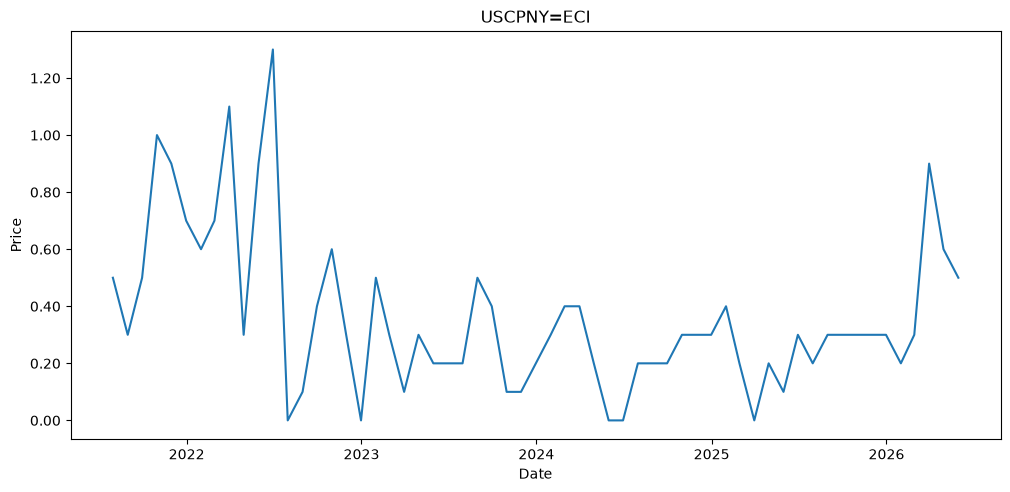

In [7]:
plt.figure(figsize=(12,6))

df_inflation["VALUE"].plot()

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))

ax.set_xlabel("Date", loc="center")
ax.set_ylabel("Price", loc="center")
ax.set_title("USCPNY=ECI")


plt.xticks(rotation=0, ha="center")
plt.show()

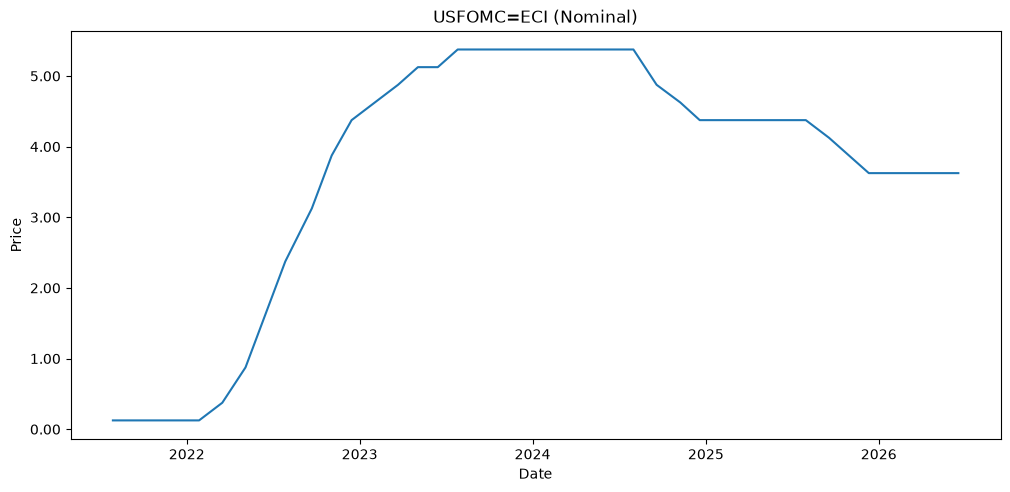

In [23]:
plt.figure(figsize=(12,6))

df_interest["VALUE"].plot()

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))

ax.set_xlabel("Date", loc="center")
ax.set_ylabel("Price", loc="center")
ax.set_title("USFOMC=ECI (Nominal)")


plt.xticks(rotation=0, ha="center")
plt.show()

In [10]:
df_interest_aligned = df_interest.reindex(df_inflation.index, method="ffill")

df_real_rate = df_interest_aligned["VALUE"] - df_inflation["VALUE"]
print(df_real_rate.head())

Date
2021-07-31   -0.375
2021-08-31   -0.175
2021-09-30   -0.375
2021-10-31   -0.875
2021-11-30   -0.775
Name: VALUE, dtype: Float64


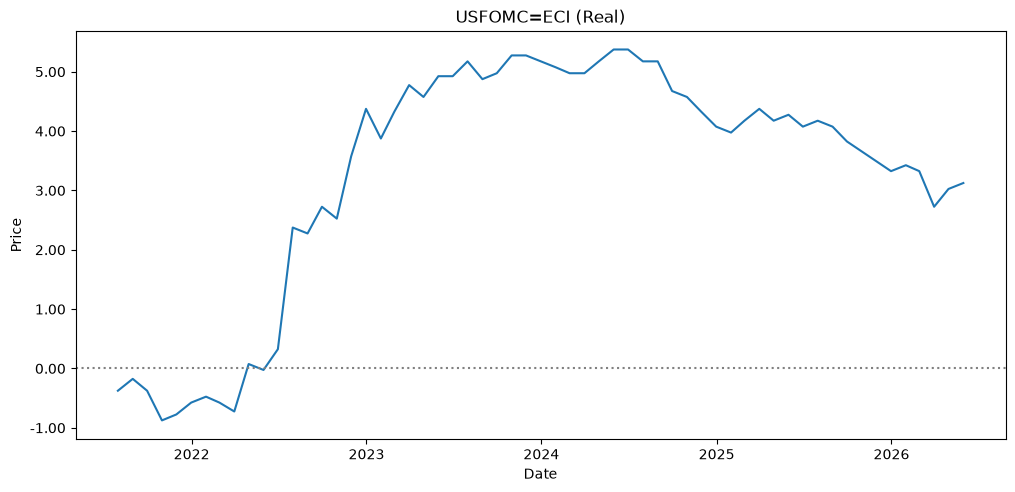

In [22]:
plt.figure(figsize=(12,6))

df_real_rate.plot()

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))

ax.axhline(linestyle=":", color="grey")
ax.set_xlabel("Date", loc="center")
ax.set_ylabel("Price", loc="center")
ax.set_title("USFOMC=ECI (Real)")


plt.xticks(rotation=0, ha="center")
plt.show()

In [ ]:
ld.close_session()